### Homework 06 - Parameter Inference
Igor Di Tota

**Introduction**

In this exercise we consider a sample of $N = 10$ independent measurements $x_1, \dots, x_N$ drawn from a Gaussian distribution $G(\mu, \sigma)$ with unknown parameters.
The variance of the sample, estimated as
$$
\hat\sigma^2 = \langle x^2 \rangle - \langle x \rangle^2 = \frac{1}{N}\sum_{i=1}^{N} (x_i - \bar{x})^2 ,
$$
which is the maximum likelihood estimator of $\sigma^2$ when the mean is also estimated from the same data, is found to be $\hat\sigma^2 = 4$.

This estimator is biased, since the Bessel correction ($N-1$ instead of $N$) is missing; however, since the frequentist limit is built directly from the probability distribution of $\hat\sigma^2$, the bias is taken into account.

The goal is to set a frequentist upper limit at 95% confidence level (CL) on the true variance $\sigma^2$.
Following the Neyman construction, the limit is derived from the probability distribution of the measured quantity $\hat\sigma^2$ for a given value of the parameter $\sigma^2$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import os
os.makedirs("images", exist_ok=True)

rng = np.random.default_rng(23)

### Distribution of the variance estimator

The estimator $\hat\sigma^2$ is itself a random variable.
As shown in the lecture, the quantity
$$
z = \frac{N \hat\sigma^2}{\sigma^2} = \frac{1}{\sigma^2}\sum_{i=1}^{N} (x_i - \bar{x})^2 = \sum_{i=1}^{N} \left(\frac{x_i - \bar{x}}{\sigma}\right)^2
$$
is distributed according to the Gamma distribution
$$
f(z; k, \lambda) = \frac{\lambda^k z^{k-1} e^{-\lambda z}}{\Gamma(k)}, \qquad k = \frac{N-1}{2}, \quad \lambda = \frac{1}{2}.
$$
This particular case of the Gamma distribution is the $\chi^2$ distribution with $N-1$ degrees of freedom: $z$ is a sum of squares of standardized Gaussian variables, with one degree of freedom lost because the mean is estimated from the same data (constraint $\sum_i (x_i - \bar{x}) = 0$).

In [`scipy.stats.gamma`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gamma.html) it corresponds to shape `a` $= k$ and `scale` $= 1/\lambda = 2$.


Some properties of the estimator follow directly:
- the expected value is $\langle \hat\sigma^2 \rangle = \frac{N-1}{N}\sigma^2$, so the ML estimator is biased;
- the distribution is asymmetric, with the most probable value at $\frac{N-3}{N}\sigma^2$;
- the probability of measuring a value below the true one is $P(\hat\sigma^2 < \sigma^2) = P(z < N)$, which for $N = 10$ is about 65%.

Because of this asymmetry, the confidence interval on $\sigma^2$ is not symmetric around the measured value.


In [4]:
N = 10
s2_meas = 4.0       # measured variance
CL = 0.95           # confidence level
alpha = 1 - CL

# Distribution of z = N * s2_hat / sigma2 using stats.gamma
k = (N - 1) / 2
z_dist = stats.gamma(a=k, scale=2)

print(f"Degrees of freedom: {N - 1}")
print(f"<z> = {z_dist.mean():.3f}   ->  <s2_hat>/sigma2 = {z_dist.mean() / N:.3f}")
print(f"Mode of z = {2 * (k - 1):.3f}   ->  s2_hat mode/sigma2 = {2 * (k - 1) / N:.3f}")
print(f"P(s2_hat < sigma2) = P(z < N) = {z_dist.cdf(N):.3f}")


Degrees of freedom: 9
<z> = 9.000   ->  <s2_hat>/sigma2 = 0.900
Mode of z = 7.000   ->  s2_hat mode/sigma2 = 0.700
P(s2_hat < sigma2) = P(z < N) = 0.650


### Monte Carlo check of the estimator distribution

Before using the Gamma distribution to compute the limit, it is checked with a Monte Carlo simulation.
A large number of experiments is generated, each one consisting of $N = 10$ measurements drawn from $G(\mu, \sigma)$.
For each experiment the variance is estimated as $\hat\sigma^2 = \frac{1}{N}\sum_i (x_i - \bar{x})^2$, without the Bessel correction, as in the definition of the exercise (`np.var` with the default `ddof=0`).

The true parameters are set to $\mu = 0$ and $\sigma^2 = 4$.
The value of $\mu$ is irrelevant, since $\hat\sigma^2$ does not depend on it.

The probability density of $\hat\sigma^2$ for a given true variance is obtained from the one of $z$ with a change of variable.
Since $z = N\hat\sigma^2/\sigma^2$ is a bijective function of $\hat\sigma^2$, the probability contained in corresponding intervals must be the same:
$$
f(\hat\sigma^2; \sigma^2)\, d\hat\sigma^2 = f_z(z)\, dz
\quad\Rightarrow\quad
f(\hat\sigma^2; \sigma^2) = f_z\big(z(\hat\sigma^2)\big) \left|\frac{dz}{d\hat\sigma^2}\right| = \frac{N}{\sigma^2}\, f_z\!\left(\frac{N \hat\sigma^2}{\sigma^2}\right),
$$
where the factor $N/\sigma^2$ is the Jacobian of the transformation.

The histogram of the generated values is compared with this density.
The mean value and the fraction of results below the true variance are also compared with the expected ones.


<s2_hat>           MC = 3.6005   expected = 3.6000
P(s2_hat < sigma2) MC = 0.6493   expected = 0.6495


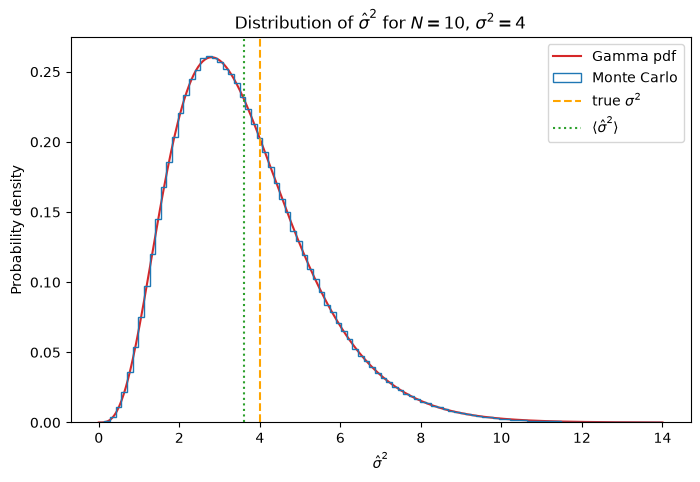

In [22]:
sigma2_true = 4.0
mu_true = 0.0
n_exp = 1000000

x = rng.normal(mu_true, np.sqrt(sigma2_true), size=(n_exp, N))
s2_hat = np.var(x, axis=1, ddof=0)

def pdf_s2(s2, sigma2):
    return N / sigma2 * z_dist.pdf(N * s2 / sigma2)

print(f"<s2_hat>           MC = {s2_hat.mean():.4f}   expected = {(N - 1) / N * sigma2_true:.4f}")
print(f"P(s2_hat < sigma2) MC = {np.mean(s2_hat < sigma2_true):.4f}   expected = {z_dist.cdf(N):.4f}")

s = np.linspace(0, 14, 500)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(s, pdf_s2(s, sigma2_true), color="tab:red", label="Gamma pdf")
ax.hist(s2_hat, bins=100, range=(0, 14), density=True, histtype="step", color="tab:blue", label="Monte Carlo")
ax.axvline(sigma2_true, color="orange", ls="--", label=r"true $\sigma^2$")
ax.axvline((N - 1) / N * sigma2_true, color="tab:green", ls=":", label=r"$\langle\hat\sigma^2\rangle$")
ax.set_xlabel(r"$\hat\sigma^2$")
ax.set_ylabel("Probability density")
ax.set_title(rf"Distribution of $\hat\sigma^2$ for $N={N}$, $\sigma^2={sigma2_true:g}$")
ax.legend()
fig.savefig("images/s2_hat_distribution.pdf", bbox_inches="tight")
plt.show()

### Analytic upper limit

In the frequentist approach, a value of the true variance $\sigma^2$ is excluded if, assuming it is true, a result as small as the measured one, or smaller, would be obtained with a probability lower than $\alpha = 1 - \text{CL}$.
Small measured values of $\hat\sigma^2$ are unlikely for large values of $\sigma^2$, so this condition defines an upper limit $\sigma^2_{ul}$:
$$
P(\hat\sigma^2 \leq \hat\sigma^2_m;\ \sigma^2_{ul}) = \alpha = 0.05,
$$
where $\hat\sigma^2_m = 4$ is the measured value.
The probability is always computed for the random variable $\hat\sigma^2$, for a fixed value of the parameter $\sigma^2$.

Using $z = N\hat\sigma^2/\sigma^2$, this probability can be written in terms of the cumulative distribution function $F_z$ of the Gamma distribution:
$$
P(\hat\sigma^2 \leq \hat\sigma^2_m;\ \sigma^2) = P\!\left(z \leq \frac{N\hat\sigma^2_m}{\sigma^2}\right) = F_z\!\left(\frac{N\hat\sigma^2_m}{\sigma^2}\right).
$$
This is a decreasing function of $\sigma^2$, so all values $\sigma^2 > \sigma^2_{ul}$ are excluded at 95% CL.

To solve this condition, let $z_\alpha$ be the point where the area under $f_z$ to its left is equal to 5%:
$$
F_z(z_\alpha) = \int_0^{z_\alpha} f_z(z)\, dz = \alpha .
$$
The condition for the limit reads $F_z\!\left(N\hat\sigma^2_m/\sigma^2_{ul}\right) = \alpha = F_z(z_\alpha)$.
Since $F_z$ is strictly increasing, two values with the same cumulative probability must coincide, so
$$
\frac{N\hat\sigma^2_m}{\sigma^2_{ul}} = z_\alpha
\quad\Rightarrow\quad
\sigma^2_{ul} = \frac{N\hat\sigma^2_m}{z_\alpha}.
$$
The value $z_\alpha$ is obtained in SciPy with the method `ppf` (percent point function), which returns the value of $z$ corresponding to a given cumulative probability.


z_alpha = 3.3251
95% CL upper limit: sigma2 < 12.030
                    sigma  < 3.468
Check: P(s2_hat <= 4; sigma2_ul) = 0.0500


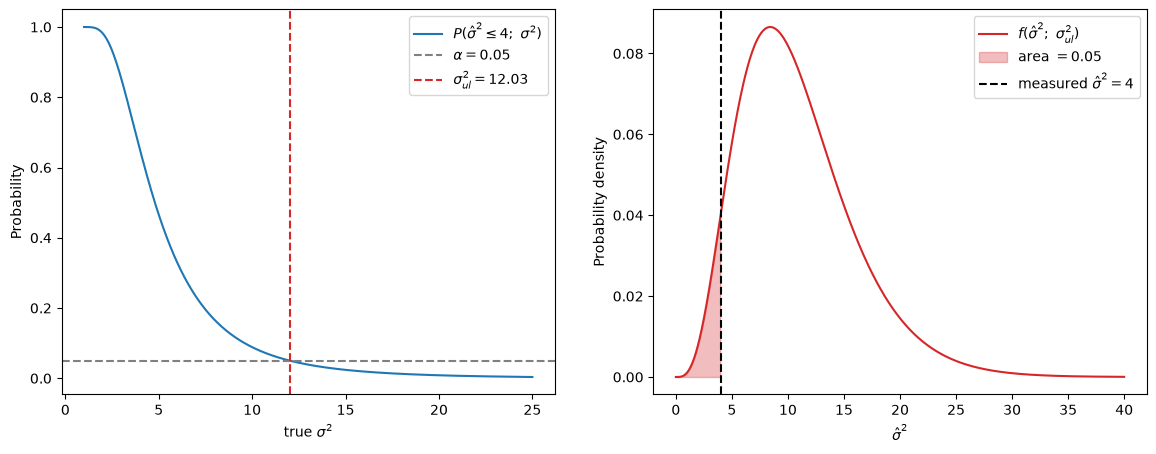

In [ ]:
def p_below(sigma2):
    "Probability of measuring s2_hat <= s2_meas for a given true variance"
    return z_dist.cdf(N * s2_meas / sigma2)


# Analytic solution with the quantile function of the Gamma distribution
z_alpha = z_dist.ppf(alpha)
sigma2_ul = N * s2_meas / z_alpha

print(f"z_alpha = {z_alpha:.4f}")
print(f"95% CL upper limit: sigma2 < {sigma2_ul:.3f}")
print(f"                    sigma  < {np.sqrt(sigma2_ul):.3f}")
print(f"Check: P(s2_hat <= {s2_meas:.0f}; sigma2_ul) = {p_below(sigma2_ul):.4f}")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
sig2 = np.linspace(1, 25, 500)
ax.plot(sig2, p_below(sig2), color="tab:blue", label=r"$P(\hat\sigma^2 \leq 4;\ \sigma^2)$")
ax.axhline(alpha, color="gray", ls="--", label=rf"$\alpha = {alpha:.2f}$")
ax.axvline(sigma2_ul, color="tab:red", ls="--", label=rf"$\sigma^2_{{ul}} = {sigma2_ul:.2f}$")
ax.set_xlabel(r"true $\sigma^2$")
ax.set_ylabel("Probability")
ax.legend()

ax = axes[1]
s = np.linspace(0, 40, 800)
mask = s <= s2_meas
ax.plot(s, pdf_s2(s, sigma2_ul), color="tab:red", label=rf"$f(\hat\sigma^2;\ \sigma^2_{{ul}})$")
ax.fill_between(s[mask], pdf_s2(s[mask], sigma2_ul), color="tab:red", alpha=0.3, label=rf"area $= {alpha:.2f}$")
ax.axvline(s2_meas, color="black", ls="--", label=r"measured $\hat\sigma^2 = 4$")
ax.set_xlabel(r"$\hat\sigma^2$")
ax.set_ylabel("Probability density")
ax.legend()

fig.savefig("images/upper_limit_analytic.pdf", bbox_inches="tight")
plt.show()
